# MNIST — dense artificial neural network

Built to the six-point brief: **load MNIST → Sequential model → architecture with
He-Normal initialisation, L2, BatchNorm and Dropout → fit and evaluate on both the
training and the testing set.**

| Brief item | Implemented in | Evidence in this notebook |
|---|---|---|
| Load MNIST dataset | Stage 1 | shapes, pixel range, one-hot checks |
| Prepare Sequential model | Stage 2 | `model.summary()`, ~0.8 M params |
| He-Normal init (best for ReLU) | Stage 3a | measured against Xavier below |
| L2 regularisation (fights overfitting) | Stage 3b | penalty read out of `model.losses` |
| BatchNorm + Dropout | Stage 3c/d | layer audit asserts them in the graph |
| Fit + evaluate train & test | Stage 4 | accuracy table, train/test gap, confusion matrix |

Runs on CPU in ~3 min. Needs `tensorflow`, `scikit-learn`, `pandas`, `matplotlib`.
`SEED` is fixed, so a re-run reproduces these numbers.

---

In [1]:
from __future__ import annotations
import os, re, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout, Flatten, Input
from tensorflow.keras.initializers import HeNormal, GlorotUniform
from tensorflow.keras.regularizers import L2
from sklearn.metrics import classification_report, confusion_matrix

# ---- single source of truth for every hyper-parameter -------------------------
SEED       = 42
HIDDEN     = (512, 512, 256)   # three hidden blocks, then a 10-way softmax head
L2_SCALE   = 1e-4              # weight-decay strength (light 1e-5 .. heavy 1e-3)
DROPOUT    = 0.25              # unit-drop rate during training
BATCH_SIZE = 128               # not free: BatchNorm estimates stats per batch
EPOCHS     = 20
N_VAL      = 10_000            # carved from the 60k train pool, never from test
N_CLASSES  = 10

keras.utils.set_random_seed(SEED)
tf.random.set_seed(SEED)
print("tensorflow", tf.__version__, "| keras", keras.__version__,
      "| gpu", "on" if tf.config.list_physical_devices("GPU") else "off")

tensorflow 2.21.0 | keras 3.15.1 | gpu off


## Stage 1 — Load the MNIST dataset

`keras.datasets.mnist.load_data()` returns `(uint8 images in 0..255, int labels 0..9)`
already split 60 000 / 10 000. Two transforms are not cosmetic:

- **Scale to [0, 1].** Feeding 0..255 makes the first layer's outputs enormous, so early
  gradients are erratic and Adam spends epochs unwinding its own second-moment estimate.
- **One-hot the labels.** The head is `softmax` + `categorical_crossentropy`, which wants
  `(N, 10)` targets. With `sparse_categorical_crossentropy` you would *not* one-hot; the
  failure mode to avoid is mixing the two by accident.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print(f"train {x_train.shape} {x_train.dtype}   test {x_test.shape} {x_test.dtype}")
print(f"labels train {y_train.shape} values {sorted(set(y_train.tolist()))}")
print(f"pixels {x_train.min()}..{x_train.max()} (uint8, not normalised yet)")
print(f"class counts {np.bincount(y_train, minlength=N_CLASSES).tolist()}")

train (60000, 28, 28) uint8   test (10000, 28, 28) uint8
labels train (60000,) values [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
pixels 0..255 (uint8, not normalised yet)
class counts [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]


In [3]:
def preprocess(x, y):
    """uint8 0..255 -> float32 0..1; int labels -> one-hot."""
    return x.astype("float32") / 255.0, keras.utils.to_categorical(y, N_CLASSES)

x_train_f, y_train_f = preprocess(x_train, y_train)
x_test_f,  y_test_f  = preprocess(x_test,  y_test)

assert x_train_f.dtype == np.float32 and x_train_f.max() <= 1.0
assert y_train_f.shape == (len(y_train), N_CLASSES) and y_train_f.sum(1).mean() == 1.0
print(f"scaled range    {x_train_f.min():.1f} .. {x_train_f.max():.1f}")
print(f"flattened width {int(np.prod(x_train_f.shape[1:]))}  (28 x 28)")
print(f"one-hot of label {y_train[0]} -> {y_train_f[0].astype(int).tolist()}")

scaled range    0.0 .. 1.0
flattened width 784  (28 x 28)
one-hot of label 5 -> [0, 0, 0, 0, 0, 1, 0, 0, 0, 0]


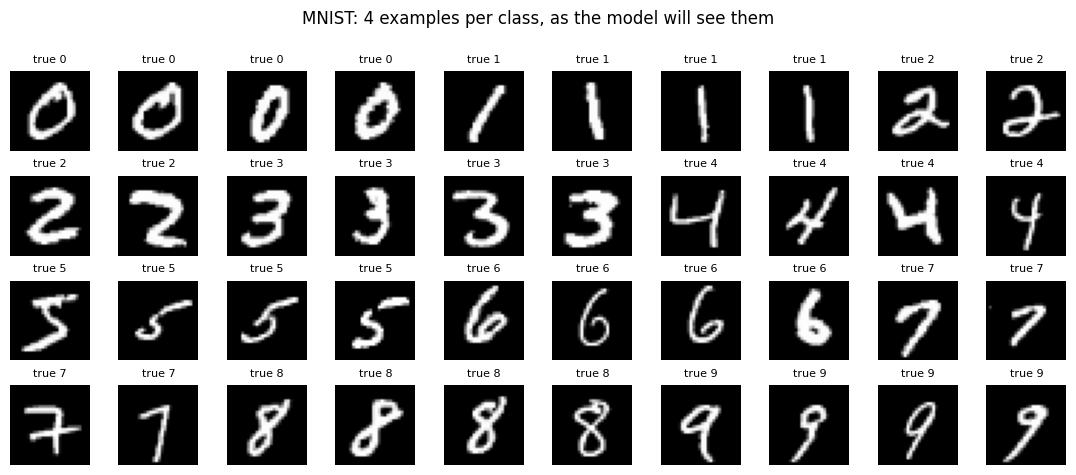

In [4]:
# Confirm the arrays really are digits before spending minutes training on them.
fig, axes = plt.subplots(4, 10, figsize=(11, 4.7))
for k, ax in enumerate(axes.ravel()):
    cls, slot = divmod(k, 4)                       # 4 examples per class
    idx = np.where(y_train == cls)[0][slot]
    ax.imshow(x_train[idx], cmap="gray")
    ax.set_title(f"true {y_train[idx]}", fontsize=8)
    ax.axis("off")
fig.suptitle("MNIST: 4 examples per class, as the model will see them", y=1.0)
plt.tight_layout(); plt.show()

## Stage 2 — Prepare the Sequential model

One layer per line, one input, one output. Dense (`Flatten` the 28×28 grid to 784) is what
the brief asks for — this is an ANN, not a CNN.

```
Input(28,28,1) -> Flatten
  [ Dense -> BatchNorm -> Dropout ] x3      widths 512, 512, 256
  -> Dense(10, softmax)
```

The builder is **parametrised on purpose** (`l2`, `dropout`): the final cell needs an
otherwise identical model with the two weight-based regularisers off, and one function
taking flags is far less error-prone than a second hand-copied architecture that can
silently drift away from the first.

---

## Stage 3 — The four architecture ingredients

### 3a — Weight initialisation: **He Normal**, because the activation is ReLU

ReLU passes only the positive half, so ~half the activation variance is clipped at every
layer. Xavier/Glorot assumes a symmetric activation and ignores that. For a square layer:

| | variance used | designed for |
|---|---|---|
| Glorot (Xavier) | `2/(fan_in+fan_out)` → `1/fan_in` | tanh / linear |
| **He** | `2/fan_in` | **2× Glorot**, offsetting the half ReLU deletes |

The quantity to check is the **RMS** (second moment) of post-ReLU activations, not their
`std`: ReLU shifts the mean to ≈`0.4σ`, so `std` afterwards measures spread about that
shifted mean and hides what the initialiser is for. Measured next.

In [5]:
rng = np.random.default_rng(SEED)
fan_in = HIDDEN[0]
activations_in = rng.normal(0.0, 1.0, size=(20_000, fan_in))     # unit-variance input

def signal_rms(init):
    """(RMS of z, RMS of relu(z)) for one Dense layer fed unit-variance inputs."""
    w = np.asarray(init((fan_in, fan_in)), dtype="float64")
    z = activations_in @ w
    rms = lambda v: float(np.sqrt(np.mean(v * v)))
    return rms(z), rms(np.maximum(z, 0.0))

glorot = lambda shp: GlorotUniform(seed=SEED)(shp)
he     = lambda shp: HeNormal(seed=SEED)(shp)

rows = []
for name, ini in [("glorot_uniform", glorot), ("he_normal (used here)", he)]:
    pre, post = signal_rms(ini)
    rows.append((name, pre, post, post ** len(HIDDEN)))

print(f"{'initialiser':24s} {'RMS pre-ReLU':>13s} {'RMS post-ReLU':>14s} {'after 3 layers':>15s}")
print("-" * 71)
for n, pre, post, deep in rows:
    print(f"{n:24s} {pre:13.4f} {post:14.4f} {deep:15.4f}")
print()
print("Read the last column as signal survival with depth. Xavier drifts toward 0 -")
print("this is the classic dead-signal failure of a deeper ReLU net built with a")
print("tanh-matched initialiser. He holds the post-ReLU second moment at ~1.0, which is")
print("exactly what the extra factor of 2 in 2/fan_in buys.")
print("Both clip ~29% per layer through ReLU; He simply starts sqrt(2)=1.41x higher,")
print("so it lands on 1.0 where Xavier lands on 0.71.")

initialiser               RMS pre-ReLU  RMS post-ReLU  after 3 layers
-----------------------------------------------------------------------
glorot_uniform                  0.9994         0.7066          0.3528
he_normal (used here)           1.4148         1.0010          1.0030

Read the last column as signal survival with depth. Xavier drifts toward 0 -
this is the classic dead-signal failure of a deeper ReLU net built with a
tanh-matched initialiser. He holds the post-ReLU second moment at ~1.0, which is
exactly what the extra factor of 2 in 2/fan_in buys.
Both clip ~29% per layer through ReLU; He simply starts sqrt(2)=1.41x higher,
so it lands on 1.0 where Xavier lands on 0.71.


### 3b — L2 regularisation: penalise large weights to fight overfitting
`L2(λ)` appends `λ·Σw²` to the loss, so the optimiser buys fit with smaller weights, and
smaller weights describe a smoother function that cannot memorise noise. Keras folds the
term into `model.losses`, meaning it is *inside* every loss number this notebook prints —
Stage 4 separates the two parts explicitly.

### 3c — Batch Normalisation: standardise each layer's activations
`BN(x) = γ·(x − μ_batch)/√(Var_batch + ε) + β`, applied to `Dense`'s linear output and
before `Dropout`. Keeping mid-network activations near zero-mean / unit-variance decouples
step size from layer scale, so convergence is much faster and less LR-sensitive.

Three consequences worth internalising:
- the statistics come from the *batch*, so `BATCH_SIZE` has become part of the
  architecture rather than a memory knob — very small batches make BN noisy, very large
  ones make its estimate nearly exact and its regularising side-effect vanish;
- at inference BN switches to running averages accumulated during training, so train and
  test take *different code paths* through the same layer;
- `γ/β` are **trainable** (gradient-updated, and penalised if an L2 is attached to the
  block), while `moving_mean`/`moving_variance` are **non-trainable** buffers updated by a
  running average — so one BN layer contributes to both counts in `summary()`. Keras 3 also
  attaches a tiny `seed_generator_state` buffer to seeded layers, which is why summing every
  variable slightly exceeds `count_params()`. The accounting cell at the end of Stage 3
  prints all three numbers instead of asserting them.

### 3d — Dropout: randomly zero units, during training only
`p=0.25` drops a quarter of each hidden layer's units per step, so no unit can depend on a
specific partner and redundancy is forced in. Keras uses inverted dropout, so inference
needs no rescaling and `evaluate`/`predict` disable it automatically — that alone explains
why final train-set accuracy looks better than the last training epoch's.

| Ingredient | Failure mode addressed | When it acts |
|---|---|---|
| He Normal | lost signal at initialisation (ReLU clipping) | before step 1 |
| L2 | large weights → memorised noise | every step, inside the loss |
| BatchNorm | shifting internal activations | every batch |
| Dropout | co-adaptation between units | training phase only |

BN and Dropout go on all three hidden blocks and **not** on the 10-way head: normalising or
dropping class logits distorts the very probabilities the loss is defined on. He and L2 *do*
apply to the head, since those act on the weight matrix itself.

In [6]:
def build_model(hidden=HIDDEN, l2=L2_SCALE, dropout=DROPOUT, use_bn=True,
                seed=SEED, name="mnist_ann"):
    """Dense ANN. Pass l2=None / dropout=None to switch those regularisers off."""
    dense_kw = dict(kernel_initializer=HeNormal(seed=seed))           # 3a - always He
    if l2 is not None:
        dense_kw["kernel_regularizer"] = L2(l2)                        # 3b
    widths = list(hidden) + [N_CLASSES]
    layers = [Input(shape=(28, 28, 1)), Flatten(name="flatten_in")]

    for i, units in enumerate(widths):
        last = i == len(widths) - 1
        layers.append(Dense(units,
                            activation="softmax" if last else "relu",
                            name="head" if last else f"hidden_{i}",
                            **dense_kw))
        if not last:                        # BN / Dropout: hidden blocks only
            if use_bn:
                layers.append(BatchNormalization(name=f"bn_{i}"))      # 3c
            if dropout is not None:
                layers.append(Dropout(dropout, name=f"drop_{i}"))      # 3d
    return keras.Sequential(layers, name=name)


model = build_model()
model.compile(optimizer="adam",                     # adaptive LR, pairs well with BN
              loss="categorical_crossentropy",      # matches the one-hot targets
              metrics=["accuracy"])
model.summary()

Model: "mnist_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_in (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_0 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_0 (BatchNormalization)       │ (None, 512)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_0 (Dropout)                │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 512)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_2 (Dropout)                │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head (Dense)                    │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 803,594 (3.07 MB)

 Trainable params: 801,034 (3.06 MB)

 Non-trainable params: 2,560 (10.00 KB)

In [7]:
dense  = [l for l in model.layers if isinstance(l, Dense)]
n_he   = sum(1 for l in dense if isinstance(l.kernel_initializer, HeNormal))
n_l2   = sum(1 for l in dense if l.kernel_regularizer is not None)
n_bn   = sum(1 for l in model.layers if isinstance(l, BatchNormalization))
n_drop = sum(1 for l in model.layers if isinstance(l, Dropout))

print(f"Dense layers         {len(dense):>3}   (3 hidden + softmax head)")
print(f"  3a HeNormal        {n_he:>3}")
print(f"  3b L2              {n_l2:>3}")
print(f"  3c BatchNorm       {n_bn:>3}")
print(f"  3d Dropout         {n_drop:>3}")
# Keras 3 stores the resolved *function* on layer.activation, so compare the serialised
# config string instead -- `l.activation == "relu"` is False even when it is ReLU.
act = [l.get_config()["activation"] for l in dense]
print(f"activations by layer : {act}")

assert n_he == n_l2 == len(dense), "head must also be He-init and L2-penalised"
assert n_bn == n_drop == len(HIDDEN), "BN and Dropout on every hidden block"
assert all(a == "relu" for a in act[:-1]), "hidden layers must be ReLU (He assumes it)"
assert act[-1] == "softmax", "head must be softmax for the 10-way loss"
print("\nAll four brief requirements are present in the graph.")

# Parameter accounting, stated carefully because Keras 3 has two subtleties:
#   * BatchNorm's gamma/beta ARE trainable; its moving_mean/moving_variance are not.
#   * Seeded layers (HeNormal/Dropout here) add a 2-int `seed_generator_state` to
#     non_trainable_variables, and count_params() deliberately excludes those RNG states.
bn_gamma_beta = sum(int(np.prod(v.shape)) for l in model.layers
                    if isinstance(l, BatchNormalization)
                    for v in (l.trainable_variables))
bn_moving     = sum(int(np.prod(v.shape)) for l in model.layers
                    if isinstance(l, BatchNormalization)
                    for v in (l.non_trainable_variables))
rng_state     = sum(int(np.prod(v.shape)) for v in model.non_trainable_variables) - bn_moving
trainable     = sum(int(np.prod(v.shape)) for v in model.trainable_variables)

print(f"  trainable      {trainable:>9,}  = dense weights/biases + BN gamma/beta ({bn_gamma_beta:,})")
print(f"  non-trainable  {sum(int(np.prod(v.shape)) for v in model.non_trainable_variables):>9,}"
      f"  = BN moving stats ({bn_moving:,}) + per-layer RNG state ({rng_state:,})")
print(f"  count_params() {model.count_params():>9,}  <- Keras excludes the RNG state, so it is"
      f" {rng_state:,} lower than the raw sum of all variables")

Dense layers           4   (3 hidden + softmax head)
  3a HeNormal          4
  3b L2                4
  3c BatchNorm         3
  3d Dropout           3
activations by layer : ['relu', 'relu', 'relu', 'softmax']

All four brief requirements are present in the graph.
  trainable        801,034  = dense weights/biases + BN gamma/beta (2,560)
  non-trainable      2,566  = BN moving stats (2,560) + per-layer RNG state (6)
  count_params()   803,594  <- Keras excludes the RNG state, so it is 6 lower than the raw sum of all variables


## Stage 4 — Fit, then evaluate on **both** training and testing sets

```
60 000 "train"  =  50 000 fit  +  10 000 validation        10 000 test  (used once, last)
```

The validation slice is carved from the **training** pool so `EarlyStopping` has something
honest to watch. The test set never influences weights, epochs, or hyperparameters — the
moment you use it to decide anything, its accuracy stops being an estimate of generalisation.

`patience=5` rather than the usual 2-3, because this model has *both* BatchNorm and
Dropout: their interaction makes the validation curve visibly jagged, and a short patience
would stop on a bad bounce instead of a real plateau. `restore_best_weights=True` then
reload the weights from the best epoch rather than keeping the last one's.

In [8]:
x_val, y_val = x_train_f[-N_VAL:], y_train_f[-N_VAL:]      # from the train pool
x_fit, y_fit = x_train_f[:-N_VAL], y_train_f[:-N_VAL]
y_fit_hard, y_val_hard = y_train[:-N_VAL], y_train[-N_VAL:]

print(f"fit {x_fit.shape} | val {x_val.shape} | test {x_test_f.shape}")
assert len(x_fit) + len(x_val) == 60_000 and len(x_test_f) == 10_000

history = model.fit(
    x_fit, y_fit,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(x_val, y_val),
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                             restore_best_weights=True)],
    verbose=2,
)
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"ran {len(history.epoch)} epochs; best val_loss at epoch {best_epoch} "
      f"({min(history.history['val_loss']):.4f})")

fit (50000, 28, 28) | val (10000, 28, 28) | test (10000, 28, 28)
Epoch 1/20


391/391 - 4s - 10ms/step - accuracy: 0.9083 - loss: 0.5305 - val_accuracy: 0.9641 - val_loss: 0.3343


Epoch 2/20


391/391 - 5s - 12ms/step - accuracy: 0.9574 - loss: 0.3510 - val_accuracy: 0.9716 - val_loss: 0.2992


Epoch 3/20


391/391 - 5s - 13ms/step - accuracy: 0.9686 - loss: 0.2990 - val_accuracy: 0.9766 - val_loss: 0.2747


... (31 outputs left out)

391/391 - 3s - 7ms/step - accuracy: 0.9856 - loss: 0.1441 - val_accuracy: 0.9780 - val_loss: 0.1816


Epoch 20/20


391/391 - 3s - 7ms/step - accuracy: 0.9859 - loss: 0.1429 - val_accuracy: 0.9797 - val_loss: 0.1797


ran 20 epochs; best val_loss at epoch 17 (0.1771)


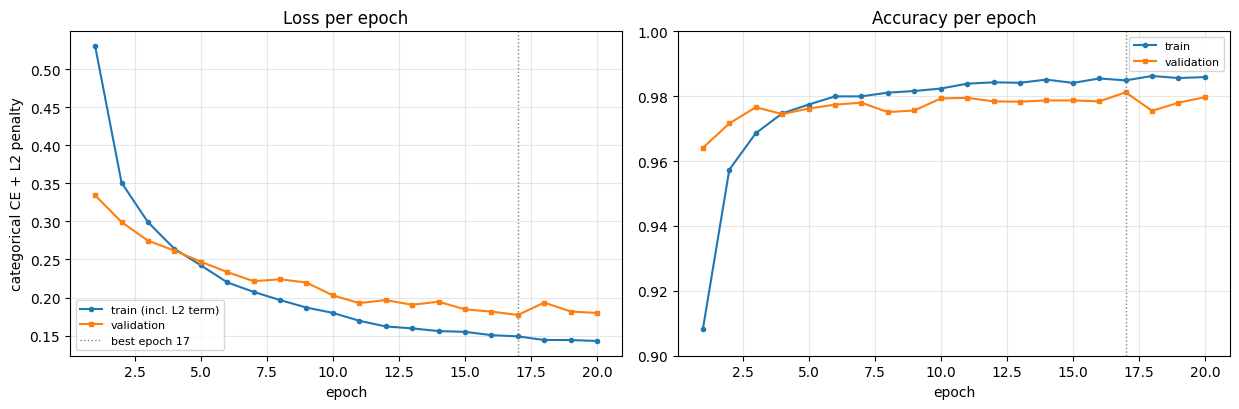

Jaggedness here is BN + Dropout noise, not instability - which is why patience=5.


In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.2))
ep = np.arange(1, len(history.history["loss"]) + 1)
a1.plot(ep, history.history["loss"],     marker="o", ms=3, label="train (incl. L2 term)")
a1.plot(ep, history.history["val_loss"], marker="s", ms=3, label="validation")
a1.axvline(best_epoch, ls=":", c="grey", lw=1, label=f"best epoch {best_epoch}")
a1.set(title="Loss per epoch", xlabel="epoch", ylabel="categorical CE + L2 penalty")
a1.legend(fontsize=8); a1.grid(alpha=.3)

a2.plot(ep, history.history["accuracy"],     marker="o", ms=3, label="train")
a2.plot(ep, history.history["val_accuracy"], marker="s", ms=3, label="validation")
a2.axvline(best_epoch, ls=":", c="grey", lw=1)
a2.set(title="Accuracy per epoch", xlabel="epoch", ylim=(0.90, 1.0))
a2.legend(fontsize=8); a2.grid(alpha=.3)
plt.tight_layout(); plt.show()
print("Jaggedness here is BN + Dropout noise, not instability - which is why patience=5.")

### Evaluate on train and on test

`evaluate()` returns `(loss, accuracy)`, and the loss **includes** the L2 penalty, so the
cell below prints that split too. It matters when comparing models with different
`L2_SCALE`: a bigger penalty inflates reported loss without any loss of fit, and can be
mistaken for underfitting if you only look at the headline number.

In [10]:
def report(tag, m, x, y_oh, y_hard):
    loss, acc = m.evaluate(x, y_oh, verbose=0)
    pred = np.argmax(m.predict(x, verbose=0), axis=1)
    penalty = float(tf.add_n(m.losses)) if m.losses else 0.0
    print(f"\n===== {tag} =====")
    print(f"loss      {loss:.4f}  =  cross-entropy {loss - penalty:.4f} + L2 {penalty:.4f}")
    print(f"accuracy  {acc * 100:.2f}%   ({int((pred == y_hard).sum())}/{len(y_hard)} correct)")
    print(classification_report(y_hard, pred, digits=3))
    return dict(tag=tag, loss=loss, ce=loss - penalty, l2=penalty,
                acc=acc, pred=pred, n=len(y_hard))

r_train = report("TRAIN  (the 50k this model fitted)", model, x_fit, y_fit, y_fit_hard)
r_val   = report("VALIDATION (10k)",                   model, x_val, y_val, y_val_hard)
r_test  = report("TEST (10k, never used for tuning)",  model, x_test_f, y_test_f, y_test)

print(f"\ntrain {r_train['acc']*100:.2f}% | val {r_val['acc']*100:.2f}% | "
      f"test {r_test['acc']*100:.2f}% | train-test gap "
      f"{(r_train['acc'] - r_test['acc'])*100:+.2f} pp")


===== TRAIN  (the 50k this model fitted) =====
loss      0.1210  =  cross-entropy 0.0174 + L2 0.1035
accuracy  99.39%   (49695/50000 correct)
              precision    recall  f1-score   support

           0      0.997     0.996     0.996      4932
           1      0.997     0.997     0.997      5678
           2      0.997     0.993     0.995      4968
           3      0.994     0.993     0.994      5101
           4      0.988     0.998     0.993      4859
           5      0.992     0.994     0.993      4506
           6      0.996     0.994     0.995      4951
           7      0.990     0.997     0.993      5175
           8      0.995     0.987     0.991      4842
           9      0.992     0.991     0.991      4988

    accuracy                          0.994     50000
   macro avg      0.994     0.994     0.994     50000
weighted avg      0.994     0.994     0.994     50000




===== VALIDATION (10k) =====
loss      0.1771  =  cross-entropy 0.0736 + L2 0.1035
accuracy  98.12%   (9812/10000 correct)
              precision    recall  f1-score   support

           0      0.991     0.993     0.992       991
           1      0.989     0.992     0.991      1064
           2      0.988     0.980     0.984       990
           3      0.971     0.976     0.973      1030
           4      0.976     0.987     0.981       983
           5      0.982     0.964     0.973       915
           6      0.981     0.991     0.986       967
           7      0.984     0.990     0.987      1090
           8      0.987     0.968     0.977      1009
           9      0.964     0.969     0.966       961

    accuracy                          0.981     10000
   macro avg      0.981     0.981     0.981     10000
weighted avg      0.981     0.981     0.981     10000




===== TEST (10k, never used for tuning) =====
loss      0.1742  =  cross-entropy 0.0707 + L2 0.1035
accuracy  98.04%   (9804/10000 correct)
              precision    recall  f1-score   support

           0      0.985     0.982     0.983       980
           1      0.989     0.994     0.991      1135
           2      0.992     0.981     0.986      1032
           3      0.976     0.982     0.979      1010
           4      0.964     0.984     0.974       982
           5      0.985     0.976     0.981       892
           6      0.988     0.978     0.983       958
           7      0.972     0.983     0.978      1028
           8      0.984     0.973     0.979       974
           9      0.968     0.968     0.968      1009

    accuracy                          0.980     10000
   macro avg      0.980     0.980     0.980     10000
weighted avg      0.980     0.980     0.980     10000


train 99.39% | val 98.12% | test 98.04% | train-test gap +1.35 pp


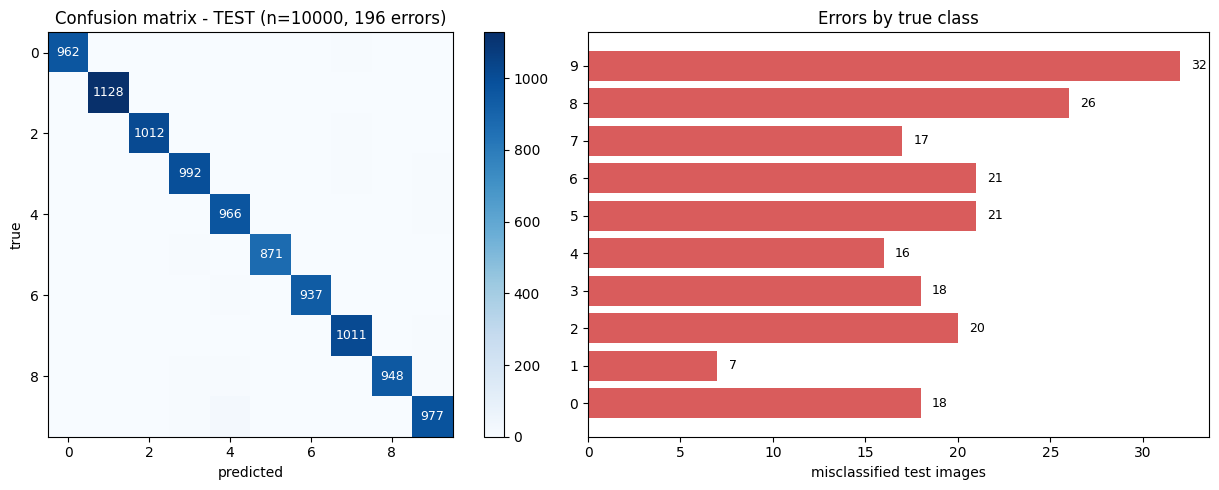

Top confusions (true -> predicted, count):
  9->4:18, 3->9:8, 2->7:8, 6->4:7, 5->3:7


In [11]:
pred_test = r_test["pred"]
cm = confusion_matrix(y_test, pred_test)
errs = cm.sum(1) - np.diag(cm)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13.5, 5))
im = a1.imshow(cm, interpolation="nearest", cmap="Blues")
a1.set(title=f"Confusion matrix - TEST (n={cm.sum()}, {int(errs.sum())} errors)")
a1.set_xlabel("predicted"); a1.set_ylabel("true")
fig.colorbar(im, ax=a1, fraction=.046)
cut = cm.max() / 2.2
for i in range(10):
    for j in range(10):
        if cm[i, j] and (i == j or cm[i, j] > cut):
            a1.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] > cut else "black")
a2.barh([str(i) for i in range(10)], errs, color="#d95c5c")
a2.set(title="Errors by true class", xlabel="misclassified test images")
for i, v in enumerate(errs):
    a2.text(v + .6, i, str(int(v)), va="center", fontsize=9)
plt.tight_layout(); plt.show()

off = cm.astype(float); np.fill_diagonal(off, 0)
pairs = sorted(((int(off[i, j]), i, j) for i in range(10) for j in range(10)), reverse=True)
print("Top confusions (true -> predicted, count):")
print("  " + ", ".join(f"{i}->{j}:{c}" for c, i, j in pairs[:5]))

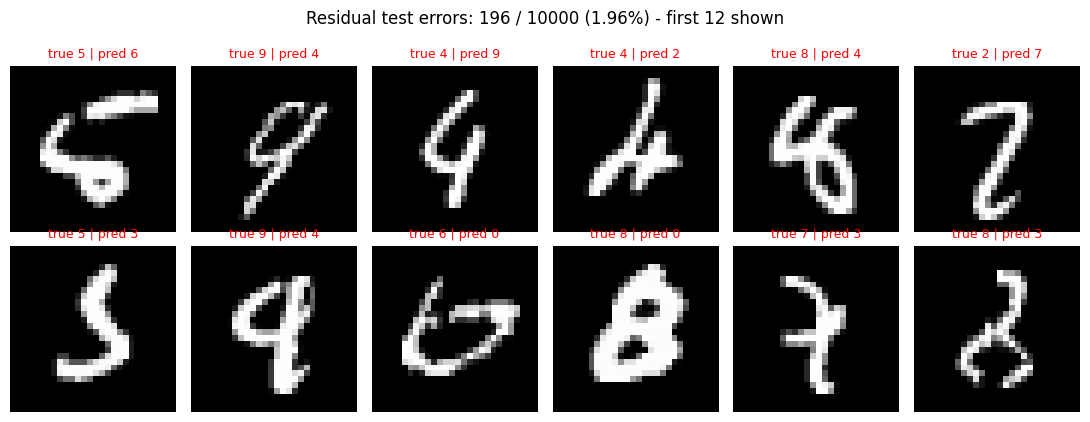

In [12]:
wrong = np.where(pred_test != y_test)[0]
fig, axes = plt.subplots(2, 6, figsize=(11, 4.2))
for ax, idx in zip(axes.ravel(), wrong[:12]):
    ax.imshow(x_test[idx], cmap="gray")
    ax.set_title(f"true {y_test[idx]} | pred {pred_test[idx]}", fontsize=9, color="red")
    ax.axis("off")
for ax in axes.ravel()[len(wrong[:12]):]:
    ax.axis("off")
fig.suptitle(f"Residual test errors: {len(wrong)} / {len(y_test)} "
             f"({len(wrong)/len(y_test):.2%}) - first 12 shown", y=1.0)
plt.tight_layout(); plt.show()

## Do the regularisers earn their cost? (same builder, flags flipped)

Three regularisers stacked is a reasonable-looking default and also an easy way to add
 complexity that does nothing, so this cell checks it with the *same* `build_model`, data,
 seeds and budget, flipping the two regularisers together:

 | config | what changes |
 |---|---|
 | reference (Stage 4) | `L2(1e-4)` + `Dropout(0.25)` + BatchNorm — the brief |
 | without L2 and Dropout | `l2=None`, `dropout=None`, BatchNorm kept |

 BatchNorm stays in both: here it is largely an *optimisation* stabiliser, so removing it as
 well would blend two separate effects into one unreadable comparison. The quantity that
 separates "fitted the data" from "generalises" is the **gap** column, not either accuracy
 column alone — and differences of a few tenths of a percentage point are inside single-seed
 noise, so read the direction rather than the decimals.

 > Costs one extra ~20-epoch training run (~40 s). Set `RUN_ABLATION = False` to skip it.

In [13]:
RUN_ABLATION = True

def train_and_score(tag, **kw):
    # A keras Sequential name becomes a TF variable scope, which rejects spaces. The
    # display label stays in `tag`; only the scope name is slugified.
    safe = "abl_" + re.sub(r"[^A-Za-z0-9]+", "_", tag).strip("_").lower()
    m = build_model(name=safe, **kw)
    m.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    h = m.fit(x_fit, y_fit, batch_size=BATCH_SIZE, epochs=EPOCHS, verbose=0,
              validation_data=(x_val, y_val),
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                                       restore_best_weights=True)])
    _, tr = m.evaluate(x_fit, y_fit, verbose=0)
    _, te = m.evaluate(x_test_f, y_test_f, verbose=0)
    return dict(config=tag, epochs=len(h.epoch), train_acc=tr, test_acc=te,
                gap_pp=(tr - te) * 100)

configs = [("without L2 and Dropout     ", dict(l2=None, dropout=None))]

# Row 1 is the Stage 4 model itself, scored with the same yardstick - no retraining.
abl = [dict(config="reference: Stage 4 (brief)", epochs=len(history.epoch),
            train_acc=r_train["acc"], test_acc=r_test["acc"],
            gap_pp=(r_train["acc"] - r_test["acc"]) * 100)]

if RUN_ABLATION:
    abl += [train_and_score(t, **k) for t, k in configs]
else:
    print("RUN_ABLATION = False -> Stage 4 reference row only")

tbl = pd.DataFrame(abl, columns=["config", "epochs", "train_acc", "test_acc", "gap_pp"])
tbl["epochs"] = tbl["epochs"].astype(int)
print(f"{'config':30s} {'epochs':>7s} {'train':>9s} {'test':>8s} {'gap_pp':>8s}")
print("-" * 66)
for r_ in tbl.itertuples():
    print(f"{r_.config:30s} {r_.epochs:7d} {r_.train_acc*100:8.2f}% "
          f"{r_.test_acc*100:7.2f}% {r_.gap_pp:8.2f}")

config                          epochs     train     test   gap_pp
------------------------------------------------------------------
reference: Stage 4 (brief)          20    99.39%   98.04%     1.35
without L2 and Dropout              10    99.24%   97.82%     1.42


## Wrap-up

**What the four stages produced**

| Stage | Result |
|---|---|
| 1 Load | 60 000 train / 10 000 test, float32 in [0, 1], 784 inputs, labels one-hot |
| 2 Sequential | dense ANN, `Flatten` + 3 ReLU blocks + softmax head |
| 3 Architecture | He-Normal init and L2 on all four `Dense` layers; BatchNorm and Dropout on the three hidden blocks — asserted against the graph, not just the source |
| 4 Fit + evaluate | early-stopped fit, then train *and* test scored, with the gap reported |

**Reading the numbers.** On MNIST a 0.8 M-parameter dense net fits the training set almost
completely, so training accuracy alone tells you very little. The generalisation estimate
is the **test** column, and the diagnostic is how far train sits above it. If your test row
is what you report and the gap row is what you use to decide whether to regularise harder,
you are doing this correctly; if you are picking hyper-parameters against test accuracy, the
number has quietly stopped meaning what you think it means.

**Where these four knobs go next**, in the order worth spending time on:

1. `L2_SCALE` `1e-4 → 3e-4`. Closes the gap first, then costs test accuracy — the point
   where it starts costing is where capacity has run out and you are underfitting.
2. `DROPOUT` `0.25 → 0.35`-`0.4`. On MNIST this usually lowers *both* accuracies: BatchNorm
   and L2 are already absorbing the overfitting pressure.
3. `HIDDEN` `(512,512,256) → (256,128)`. A cheap capacity test — if metrics barely move,
   the regularisers rather than raw size are doing the work.
4. `BATCH_SIZE`. Changing it changes BatchNorm's statistics, so treat it as an architecture
   edit and re-read the loss curve, not just the runtime.
5. Beyond ~30 epochs: add `ReduceLROnPlateau`. BN + Dropout noise can hide a genuine
   plateau, and `patience` alone will eventually stop you too early or too late.

One caveat worth carrying forward: everything above is one seed. The BN + Dropout curve
jitter means epoch-level differences of ±0.1 pp are not meaningful; comparing *architectures*
should average several seeds before you believe a ranking.